# IoT Sensor Anomaly Detection Using Machine Learning

## Project Overview
This project demonstrates unsupervised anomaly detection on simulated industrial sensor data using the Isolation Forest algorithm. It analyses temperature and vibration readings to identify unusual patterns that could indicate potential equipment issues.

## Objectives
- Generate simulated normal sensor readings and artificial anomalies.
- Train an Isolation Forest model to identify unusual readings.
- Evaluate model performance using a confusion matrix, precision, recall, and accuracy.
- Compare contamination settings to understand their effect on false alarms.

## Tools and Technologies
Python, NumPy, Pandas, Matplotlib, and Scikit-learn.

**Note:** This is an educational proof of concept using simulated data, not real industrial sensor measurements.

General Normal Sensor Data

## 1. Generate Normal Sensor Data

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

n = 1000

data = pd.DataFrame({
    "temperature": rng.normal(65, 4, n),
    "vibration": rng.normal(3, 0.5, n)
})

data.head()

,temperature,vibration
0,66.218868,2.970359
1,60.840064,2.635357
2,68.001805,2.792763
3,68.762259,3.316955
4,57.195859,3.001497


## 2. Visualise Normal Sensor Data

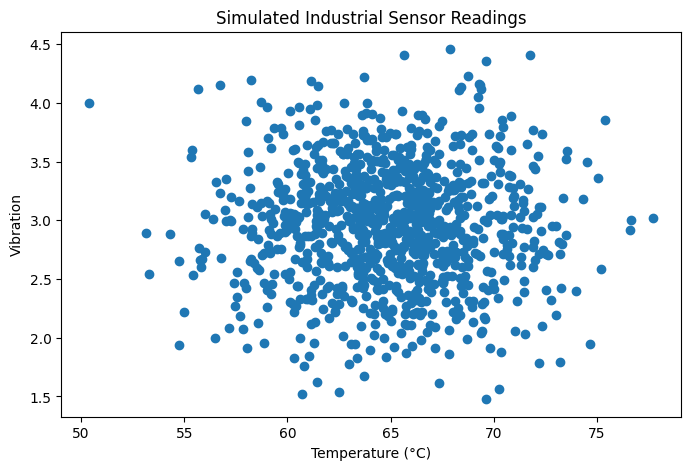

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(
    data["temperature"],
    data["vibration"]
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration")
plt.title("Simulated Industrial Sensor Readings")

plt.show()

## 3. Generate Artificial Anomalies

In [19]:
# Create 30 unusual sensor readings
anomalies = pd.DataFrame({
    "temperature": rng.uniform(85, 100, 30),
    "vibration": rng.uniform(5, 8, 30)
})

# Combine normal readings with unusual readings
data_with_anomalies = pd.concat(
    [data, anomalies],
    ignore_index=True
)

data_with_anomalies.tail()

,temperature,vibration
1025,97.892962,7.241333
1026,91.723785,5.392255
1027,89.192311,7.420833
1028,97.832130,7.810722
1029,90.848342,6.819596


## 4. Visualise the Combined Dataset

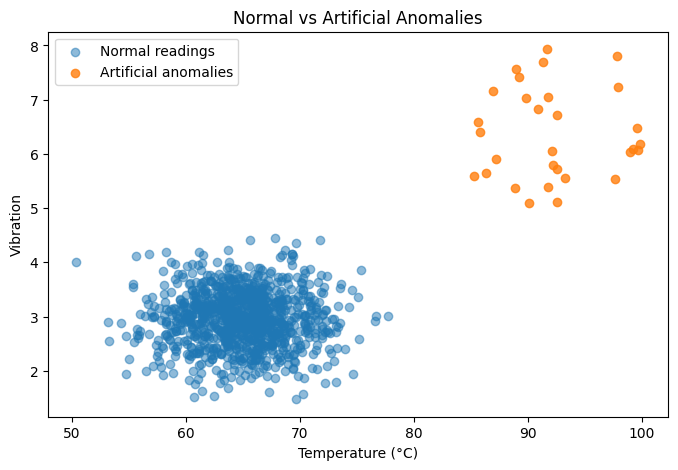

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(
    data["temperature"],
    data["vibration"],
    label="Normal readings",
    alpha=0.5
)

plt.scatter(
    anomalies["temperature"],
    anomalies["vibration"],
    label="Artificial anomalies",
    alpha=0.8
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration")
plt.title("Normal vs Artificial Anomalies")
plt.legend()
plt.show()

## 5. Train the Initial Model

In [21]:
from sklearn.ensemble import IsolationForest

# Use temperature and vibration as model features
X = data_with_anomalies[["temperature", "vibration"]]

# Create the model
model = IsolationForest(
    contamination=0.03,
    random_state=42
)

# Train the model
model.fit(X)

print("Model training complete!")

Model training complete!


## 6. Make Initial Predictions

In [22]:
# Predict anomalies
predictions = model.predict(X)

# Convert predictions into readable labels
data_with_anomalies["prediction"] = predictions

data_with_anomalies["prediction"] = (
    data_with_anomalies["prediction"]
    .map({1: "Normal", -1: "Anomaly"})
)

# Count the predictions
print(data_with_anomalies["prediction"].value_counts())

prediction
Normal     999
Anomaly     31
Name: count, dtype: int64


## 7. Visualise Initial Predictions

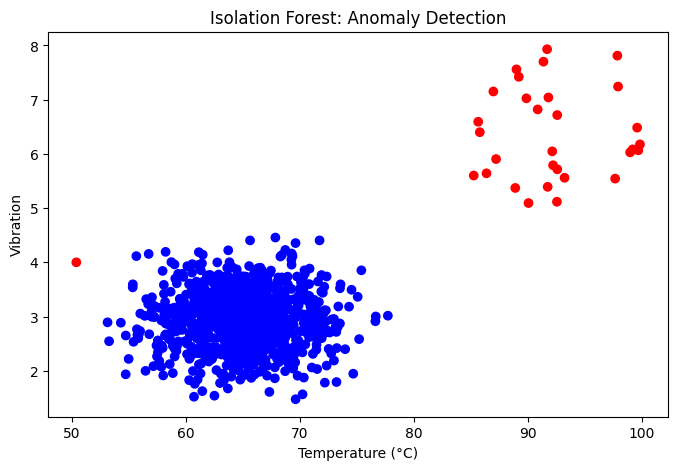

In [23]:
plt.figure(figsize=(8, 5))

colors = data_with_anomalies["prediction"].map({
    "Normal": "blue",
    "Anomaly": "red"
})

plt.scatter(
    X["temperature"],
    X["vibration"],
    c=colors
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration")
plt.title("Isolation Forest: Anomaly Detection")
plt.show()

## 8. Evaluate Initial Model

In [24]:
from sklearn.metrics import classification_report, confusion_matrix

# Actual labels: 0 = normal, 1 = artificial anomaly
actual = np.array([0] * len(data) + [1] * len(anomalies))

# Model predictions: convert Anomaly to 1 and Normal to 0
predicted = (
    data_with_anomalies["prediction"]
    .map({"Normal": 0, "Anomaly": 1})
    .to_numpy()
)

print("Confusion matrix:")
print(confusion_matrix(actual, predicted))

print("\nClassification report:")
print(classification_report(
    actual,
    predicted,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

Confusion matrix:
[[999   1]
 [  0  30]]

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      1000
     Anomaly       0.97      1.00      0.98        30

    accuracy                           1.00      1030
   macro avg       0.98      1.00      0.99      1030
weighted avg       1.00      1.00      1.00      1030



## 9. Train on Normal Data Only

In [25]:
# Train using only normal sensor readings
X_train = data[["temperature", "vibration"]]

model = IsolationForest(
    contamination=0.03,
    random_state=42
)

model.fit(X_train)

print("Model trained on normal readings only!")

Model trained on normal readings only!


## 10. Test the Model

In [26]:
# Test on all readings: normal + artificial anomalies
X_test = data_with_anomalies[["temperature", "vibration"]]

predictions = model.predict(X_test)

data_with_anomalies["prediction"] = pd.Series(predictions).map({
    1: "Normal",
    -1: "Anomaly"
}).values

print(data_with_anomalies["prediction"].value_counts())

prediction
Normal     970
Anomaly     60
Name: count, dtype: int64


## 11. Evaluate Test Performance

In [27]:
from sklearn.metrics import confusion_matrix, classification_report

# Actual labels: 0 = normal, 1 = artificial anomaly
actual = np.array([0] * len(data) + [1] * len(anomalies))

# Predicted labels: 0 = normal, 1 = anomaly
predicted = (
    data_with_anomalies["prediction"]
    .map({"Normal": 0, "Anomaly": 1})
    .to_numpy()
)

print("Confusion matrix:")
print(confusion_matrix(actual, predicted))

print("\nClassification report:")
print(classification_report(
    actual,
    predicted,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

Confusion matrix:
[[970  30]
 [  0  30]]

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.98      1000
     Anomaly       0.50      1.00      0.67        30

    accuracy                           0.97      1030
   macro avg       0.75      0.98      0.83      1030
weighted avg       0.99      0.97      0.98      1030



## 12. Visualise Test Predictions

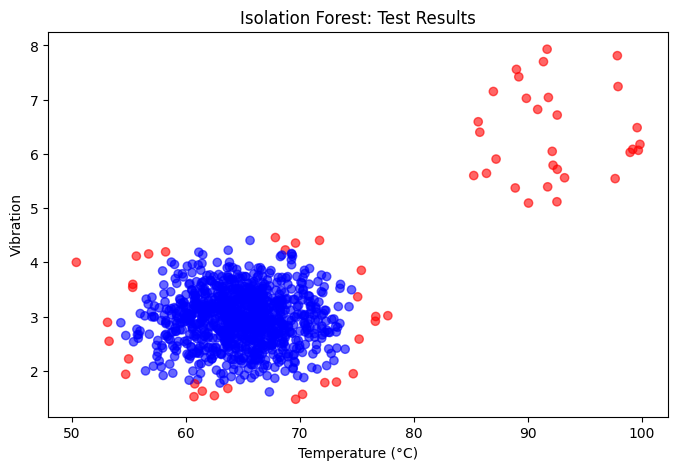

In [28]:
plt.figure(figsize=(8, 5))

colors = data_with_anomalies["prediction"].map({
    "Normal": "blue",
    "Anomaly": "red"
})

plt.scatter(
    X_test["temperature"],
    X_test["vibration"],
    c=colors,
    alpha=0.6
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration")
plt.title("Isolation Forest: Test Results")
plt.show()

## 13. Tune the Contamination Parameter

In [29]:
model = IsolationForest(
    contamination=0.01,
    random_state=42
)

model.fit(X_train)

predictions = model.predict(X_test)

data_with_anomalies["prediction"] = pd.Series(predictions).map({
    1: "Normal",
    -1: "Anomaly"
}).values

print(data_with_anomalies["prediction"].value_counts())

prediction
Normal     990
Anomaly     40
Name: count, dtype: int64


## 14. Evaluate the Tuned Model

In [30]:
predicted = (
    data_with_anomalies["prediction"]
    .map({"Normal": 0, "Anomaly": 1})
    .to_numpy()
)

print("Confusion matrix:")
print(confusion_matrix(actual, predicted))

print("\nClassification report:")
print(classification_report(
    actual,
    predicted,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))

Confusion matrix:
[[990  10]
 [  0  30]]

Classification report:
              precision    recall  f1-score   support

      Normal       1.00      0.99      0.99      1000
     Anomaly       0.75      1.00      0.86        30

    accuracy                           0.99      1030
   macro avg       0.88      0.99      0.93      1030
weighted avg       0.99      0.99      0.99      1030



## 15. Compare Model Performance

In [31]:
comparison = pd.DataFrame({
    "Contamination": [0.03, 0.01],
    "False Alarms": [30, 10],
    "Anomalies Detected": [30, 30],
    "Anomaly Precision": [0.50, 0.75],
    "Anomaly Recall": [1.00, 1.00],
    "Accuracy": [0.9709, 0.9903]
})

comparison

,Contamination,False Alarms,Anomalies Detected,Anomaly Precision,Anomaly Recall,Accuracy
0,0.03,30,30,0.50,1.0,0.9709
1,0.01,10,30,0.75,1.0,0.9903


## 16. Compare False Alarms

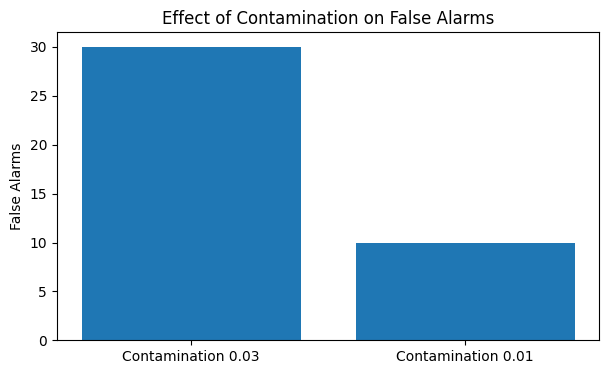

In [32]:
plt.figure(figsize=(7, 4))

plt.bar(
    ["Contamination 0.03", "Contamination 0.01"],
    [30, 10]
)

plt.ylabel("False Alarms")
plt.title("Effect of Contamination on False Alarms")
plt.show()